# Chicago taxi trips — week of 11–17 September 2023

**Summary (filled in at the end of the analysis)**

SUMMARY_PLACEHOLDER

## 1. Data loading

All figures describe **trips reported to the City of Chicago**, not total market volume (per `dataset.md`, not every trip is reported).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs('figures/analysis', exist_ok=True)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

# Chart style: one blue for the main series, orange only for a deliberate highlight, recessive grid
BLUE, ORANGE, GREY, INK = '#2a78d6', '#eb6834', '#b9b8b3', '#0b0b0b'
plt.rcParams.update({
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.grid.axis': 'y', 'grid.color': '#e6e5e1', 'grid.linewidth': 0.8,
    'axes.axisbelow': True, 'figure.dpi': 100, 'axes.titlesize': 13, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
})

raw = pd.read_csv(
    'trips.csv',
    dtype={'pickup_census_tract': 'string', 'dropoff_census_tract': 'string'},
    parse_dates=['trip_start_timestamp', 'trip_end_timestamp'],
)
print('shape:', raw.shape)
print('trip_id unique:', raw.trip_id.is_unique)
print('start range:', raw.trip_start_timestamp.min(), '->', raw.trip_start_timestamp.max())

shape: (135768, 23)
trip_id unique: True
start range: 2023-09-11 00:00:00 -> 2023-09-17 23:45:00


## 2. Data checks and cleaning

### 2.1 Missing values

In [2]:
miss = raw.isna().sum()
miss = miss[miss > 0].to_frame('missing')
miss['pct_of_rows'] = (miss.missing / len(raw) * 100).round(2)
miss

,missing,pct_of_rows
trip_end_timestamp,1,0.00
trip_seconds,33,0.02
pickup_census_tract,71404,52.59
dropoff_census_tract,73842,54.39
pickup_community_area,3815,2.81
dropoff_community_area,13794,10.16
fare,324,0.24
tips,324,0.24
tolls,324,0.24
extras,324,0.24


Notes: the five money columns (`fare`, `tips`, `tolls`, `extras`, `trip_total`) are all missing together on the same rows. The census-tract and dropoff columns are not used in this analysis (the brief says to use community areas).

### 2.2 Implausible or inconsistent values

In [3]:
money = ['fare', 'tips', 'tolls', 'extras', 'trip_total']
has_money = raw.trip_total.notna()
parts_gap = (raw.trip_total - raw[['fare', 'tips', 'tolls', 'extras']].sum(axis=1)).round(2)
speed_mph = raw.trip_miles / (raw.trip_seconds / 3600)

checks = pd.DataFrame([
    ('Money fields missing (all five together)',          (~has_money).sum()),
    ('fare = 0 or trip_total = 0 (money present)',        (has_money & ((raw.fare <= 0) | (raw.trip_total <= 0))).sum()),
    ('trip_total > $500',                                 (raw.trip_total > 500).sum()),
    ('trip_total > sum of fare+tips+tolls+extras',        (parts_gap > 0.01).sum()),
    ('trip_total < sum of parts',                         (parts_gap < -0.01).sum()),
    ('   ... largest gap above the sum of parts ($)',     parts_gap.max()),
    ('trip_miles = 0',                                    (raw.trip_miles == 0).sum()),
    ('trip_miles > 100',                                  (raw.trip_miles > 100).sum()),
    ('trip_seconds = 0',                                  (raw.trip_seconds == 0).sum()),
    ('trip_seconds missing',                              raw.trip_seconds.isna().sum()),
    ('trip_seconds > 6 hours',                            (raw.trip_seconds > 6 * 3600).sum()),
    ('Implied speed > 100 mph (seconds > 0)',             (speed_mph > 100).sum()),
    ('extras > $100',                                     (raw.extras > 100).sum()),
    ('Duplicate rows apart from trip_id',                 raw.duplicated([c for c in raw.columns if c != 'trip_id']).sum()),
], columns=['check', 'rows']).set_index('check')
checks['rows'] = [f'${v:,.2f}' if 'largest gap' in i else f'{int(v):,}' for i, v in checks['rows'].items()]
checks

,rows
check,
Money fields missing (all five together),324
fare = 0 or trip_total = 0 (money present),135
trip_total > $500,8
trip_total > sum of fare+tips+tolls+extras,"48,197"
trip_total < sum of parts,0
... largest gap above the sum of parts ($),$3.00
trip_miles = 0,"13,993"
trip_miles > 100,11
trip_seconds = 0,"2,731"


### 2.3 Cleaning decisions and assumptions

Principle: **exclude a trip only if its money fields cannot be trusted** (every answer except the pure trip counts depends on them), and apply the *same* cleaned table to all four questions so numbers agree across sections. Odd distance/duration values are flagged but **not** excluded, because no question uses `trip_miles` or `trip_seconds`.

| # | Issue | Treatment |
|---|---|---|
| A1 | All five money fields missing (mostly cash trips) | **Exclude** — no revenue can be computed |
| A2 | `fare` = 0 or `trip_total` = 0 | **Exclude** — nothing billed; 131 of the 135 are cash trips |
| A3 | `trip_total` > $500 (>20× the median) | **Exclude** — dominated by obvious entry errors (e.g. $4,444 tolls on a 1-mile trip) |
| A4 | `trip_total` is above the sum of its parts (always by ≤ $3, never below) | **Keep**, use `trip_total` as reported. The gap looks like an un-itemised surcharge (usually exactly $0.50), not an error |
| A5 | Zero or extreme `trip_miles` / `trip_seconds`, implied speed > 100 mph | **Keep** (flag only). Fares on these rows look normal; the distance/time fields are unreliable but unused |
| A6 | 92 duplicate rows apart from `trip_id` | **Keep**. Almost all are $3.25, 0-mile, 0-second cash records (repeated meter starts); `trip_id`s are unique, so we cannot tell them from genuine separate trips |
| A7 | `extras` > $100 (15 rows) | **Keep**; immaterial to totals, noted as a data-quality oddity |
| A8 | Company names with spelling variants | **Merge** the two unambiguous pairs (see below). "Taxi Affiliation Services Llc - Yell…" is left separate because it is truncated and could be a distinct brand |
| A9 | Pickup community area blank | Kept as "no pickup community area" (see Q2) — not imputed |

Other assumptions: timestamps are Chicago local time; `Prcard` is read as a prepaid card; `Mobile` as app-based payment; `Unknown`, `No Charge` and `Dispute` are kept as reported categories.

In [4]:
n0 = len(raw)
a1 = raw.trip_total.isna()
a2 = ~a1 & ((raw.fare <= 0) | (raw.trip_total <= 0))
a3 = ~a1 & ~a2 & (raw.trip_total > 500)
steps = [('Raw trips', 0), ('A1 money fields missing', a1.sum()), ('A2 zero fare or zero total', a2.sum()), ('A3 trip_total > $500', a3.sum())]

df = raw[~(a1 | a2 | a3)].copy()

company_map = {
    'Taxicab Insurance Agency, LLC': 'Taxicab Insurance Agency Llc',
    'Choice Taxi Association Inc': 'Choice Taxi Association',
}
df['company'] = df.company.replace(company_map)

df['start_date'] = df.trip_start_timestamp.dt.normalize()
df['dow'] = df.trip_start_timestamp.dt.day_name()
df['hour'] = df.trip_start_timestamp.dt.hour
df['weekend'] = df.trip_start_timestamp.dt.day_of_week >= 5

tbl = pd.DataFrame(steps, columns=['step', 'rows_removed'])
tbl['rows_remaining'] = n0 - tbl.rows_removed.cumsum()
tbl['rows_removed'] = tbl.rows_removed.map(lambda v: f'{v:,}' if v else '')
tbl['rows_remaining'] = tbl.rows_remaining.map('{:,}'.format)
print(tbl.to_string(index=False))
print(f'\nExcluded in total: {n0 - len(df):,} rows ({(n0 - len(df)) / n0:.2%}); cleaned table: {len(df):,} trips')
print('Company names merged (A8):', {k: int((raw.company == k).sum()) for k in company_map}, '-> now', df.company.nunique(), 'distinct companies (was', raw.company.nunique(), ')')
print('Taxi_ids appearing under more than one merged company:', int((df.groupby('taxi_id').company.nunique() > 1).sum()))

                      step rows_removed rows_remaining
                 Raw trips                     135,768
   A1 money fields missing          324        135,444
A2 zero fare or zero total          135        135,309
      A3 trip_total > $500            8        135,301

Excluded in total: 467 rows (0.34%); cleaned table: 135,301 trips
Company names merged (A8): {'Taxicab Insurance Agency, LLC': 2379, 'Choice Taxi Association Inc': 1064} -> now 30 distinct companies (was 32 )
Taxi_ids appearing under more than one merged company: 3


## 3. Q1 — When is demand highest?

Trips are counted by the (15-minute-rounded) start time. Hours are therefore approximate: a trip starting at 07:52 is stamped 08:00. Because a week has five weekdays but only two weekend days, the hourly comparison uses **average trips per day** for each group.

In [5]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
by_day = df.groupby('dow').size().reindex(day_order).to_frame('trips')
by_day['share_%'] = (by_day.trips / by_day.trips.sum() * 100).round(1)
wkday_avg = by_day.trips.iloc[:5].mean()
by_day['vs_weekday_avg_%'] = ((by_day.trips / wkday_avg - 1) * 100).round(1)
print(by_day.to_string())
print(f"\nAverage weekday: {wkday_avg:,.0f} trips | average weekend day: {by_day.trips.iloc[5:].mean():,.0f} trips "
      f"({by_day.trips.iloc[5:].mean() / wkday_avg - 1:.0%} vs weekday)")

# trips per hour, averaged over the days in each group
n_days = df.groupby('weekend').start_date.nunique()
hourly = (df.groupby(['weekend', 'hour']).size().unstack(0).reindex(range(24), fill_value=0)
            .div(n_days, axis=1).rename(columns={False: 'weekday_avg', True: 'weekend_avg'}))
hourly['all_week_total'] = df.groupby('hour').size().reindex(range(24), fill_value=0)
print('\nDays in each group:', n_days.to_dict())
print(hourly.round(0).astype(int).T.to_string())

           trips  share_%  vs_weekday_avg_%
dow                                        
Monday     22101    16.30              1.10
Tuesday    21964    16.20              0.50
Wednesday  22622    16.70              3.50
Thursday   22458    16.60              2.70
Friday     20167    14.90             -7.80
Saturday   12663     9.40            -42.10
Sunday     13326     9.80            -39.00

Average weekday: 21,862 trips | average weekend day: 12,994 trips (-41% vs weekday)

Days in each group: {False: 5, True: 2}
hour              0     1    2    3    4     5     6     7     8     9     10    11    12    13    14    15    16    17    18    19    20    21    22    23
weekend                                                                                                                                                    
weekday_avg      334   168   75   75  119   219   436   813  1157  1303  1273  1306  1396  1433  1493  1517  1493  1550  1459  1283  1072   846   606   435
weekend_av

In [6]:
print('Busiest 3 hours (all week):'); print(hourly.all_week_total.nlargest(3).to_string())
print('\nQuietest 3 hours (all week):'); print(hourly.all_week_total.nsmallest(3).to_string())
for g in ['weekday_avg', 'weekend_avg']:
    print(f"\n{g}: peak hour {hourly[g].idxmax()}:00 ({hourly[g].max():,.0f}/day), quietest hour {hourly[g].idxmin()}:00 ({hourly[g].min():,.0f}/day)")
# share of trips by broad period
period = pd.cut(df.hour, [-1, 5, 9, 15, 19, 23], labels=['00-05 night', '06-09 morning', '10-15 midday', '16-19 evening', '20-23 late'])
print('\nShare of trips by period, weekday vs weekend (%):')
print((pd.crosstab(period, df.weekend, normalize='columns') * 100).round(1).rename(columns={False: 'weekday', True: 'weekend'}).to_string())
# sensitivity: raw vs clean day counts
print('\nRaw vs cleaned trips by day (cleaning effect):')
print(pd.DataFrame({'raw': raw.groupby(raw.trip_start_timestamp.dt.day_name()).size(), 'clean': by_day.trips}).reindex(day_order).to_string())

Busiest 3 hours (all week):
hour
17    9468
15    9433
14    9249

Quietest 3 hours (all week):
hour
3    630
2    770
4    862

weekday_avg: peak hour 17:00 (1,550/day), quietest hour 3:00 (75/day)

weekend_avg: peak hour 15:00 (924/day), quietest hour 3:00 (127/day)

Share of trips by period, weekday vs weekend (%):
weekend        weekday  weekend
hour                           
00-05 night       4.50     9.50
06-09 morning    17.00    10.80
10-15 midday     38.50    37.60
16-19 evening    26.50    25.40
20-23 late       13.50    16.70

Raw vs cleaned trips by day (cleaning effect):
             raw  clean
Monday     22190  22101
Tuesday    22040  21964
Wednesday  22694  22622
Thursday   22531  22458
Friday     20226  20167
Saturday   12719  12663
Sunday     13368  13326


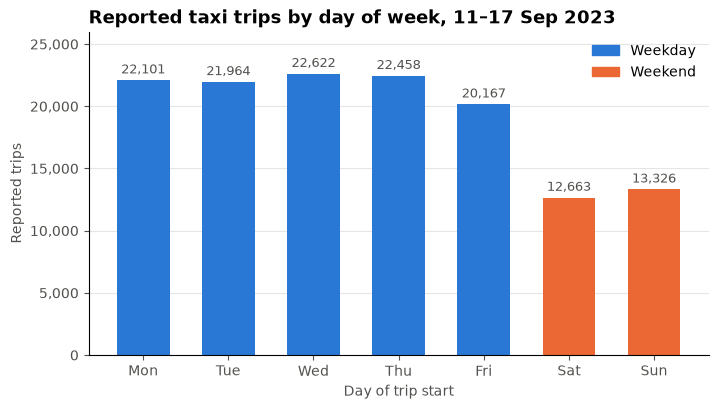

In [7]:
from matplotlib.patches import Patch
fig, ax = plt.subplots(figsize=(8, 4.2))
colors = [BLUE] * 5 + [ORANGE] * 2
bars = ax.bar([d[:3] for d in day_order], by_day.trips, color=colors, width=0.62)
for b, v in zip(bars, by_day.trips):
    ax.text(b.get_x() + b.get_width() / 2, v + 300, f'{v:,}', ha='center', va='bottom', fontsize=9, color='#52514e')
ax.set_title('Reported taxi trips by day of week, 11–17 Sep 2023')
ax.set_xlabel('Day of trip start')
ax.set_ylabel('Reported trips')
ax.set_ylim(0, 26000)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
ax.legend(handles=[Patch(color=BLUE, label='Weekday'), Patch(color=ORANGE, label='Weekend')], frameon=False, loc='upper right')
plt.savefig('figures/analysis/01_trips_by_day.png', dpi=150, bbox_inches='tight')
plt.show()

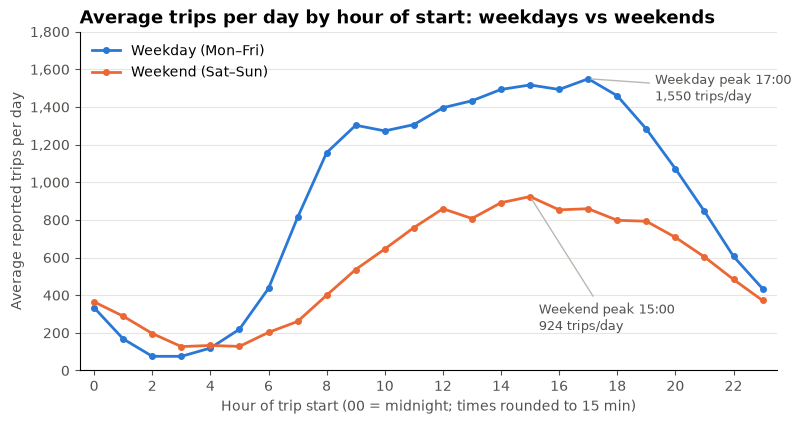

In [8]:
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.plot(hourly.index, hourly.weekday_avg, color=BLUE, lw=2, marker='o', ms=4, label='Weekday (Mon–Fri)')
ax.plot(hourly.index, hourly.weekend_avg, color=ORANGE, lw=2, marker='o', ms=4, label='Weekend (Sat–Sun)')
ax.annotate('Weekday peak 17:00\n1,550 trips/day', (17, 1550), xytext=(19.3, 1500), fontsize=9, color='#52514e', va='center',
            arrowprops=dict(arrowstyle='-', color=GREY))
ax.annotate('Weekend peak 15:00\n924 trips/day', (15, 924), xytext=(15.3, 280), fontsize=9, color='#52514e', ha='left', va='center',
            arrowprops=dict(arrowstyle='-', color=GREY))
ax.set_title('Average trips per day by hour of start: weekdays vs weekends')
ax.set_xlabel('Hour of trip start (00 = midnight; times rounded to 15 min)')
ax.set_ylabel('Average reported trips per day')
ax.set_xticks(range(0, 24, 2))
ax.set_ylim(0, 1800); ax.set_xlim(-0.5, 23.5)
ax.yaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
ax.legend(frameon=False, loc='upper left')
plt.savefig('figures/analysis/02_trips_by_hour.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway (Q1).** Weekday demand is steady Monday–Thursday (about 22,000 reported trips a day; Wednesday is the busiest at 22,622), dips about 8% on Friday and falls roughly 40% on the weekend (Saturday is the quietest day at 12,663). Within the day, weekdays climb sharply from 06:00 to 09:00, then stay on a plateau until early evening, peaking at 17:00 (about 1,550 trips); weekends build more slowly and peak mid-afternoon at 15:00 (about 920). The quietest time of all is 02:00–04:00 (about 75 trips an hour on weekdays). Overnight (00:00–05:00) weekends hold up better than weekdays: 9.5% of weekend trips against 4.5% on weekdays. Caveat: the "weekend" group is defined by calendar day, so it includes the late-Friday-night spill-over into early Saturday.

## 4. Q2 — Where do trips start?

Pickup community areas are shown by their numeric code (no outside lookup of names, per the brief).

In [9]:
n = len(df)
no_area = df.pickup_community_area.isna()
print(f'Trips with no pickup community area: {no_area.sum():,} of {n:,} = {no_area.mean():.2%}')
has_tract = no_area & df.pickup_census_tract.notna()
print(f'  ...of which have a pickup census tract anyway: {has_tract.sum():,} ({(has_tract & (df.pickup_census_tract == "17031770700")).sum()} in tract 17031770700, which has a centroid; the other {(has_tract & (df.pickup_census_tract != "17031770700")).sum()} have no centroid either). Left blank, not imputed.')
print(f'  ...of which have no pickup centroid at all: {(no_area & df.pickup_centroid_latitude.isna()).sum():,}')
print(f'  Their revenue share: {df.loc[no_area, "trip_total"].sum() / df.trip_total.sum():.2%}; average trip_total ${df.loc[no_area, "trip_total"].mean():.2f} vs ${df.loc[~no_area, "trip_total"].mean():.2f} for trips with an area')

area = (df.dropna(subset=['pickup_community_area']).assign(area=lambda x: x.pickup_community_area.astype(int))
          .groupby('area').agg(trips=('trip_id', 'size'), revenue=('trip_total', 'sum')))
area['trip_share_%'] = area.trips / n * 100
area['revenue_share_%'] = area.revenue / df.trip_total.sum() * 100
area['avg_trip_total'] = area.revenue / area.trips
print('\nCommunity areas with at least one trip:', len(area))
top_trips = area.sort_values('trips', ascending=False).head(10)
top_rev = area.sort_values('revenue', ascending=False).head(10)
fmt = {'trips': '{:,.0f}'.format, 'revenue': '${:,.0f}'.format, 'trip_share_%': '{:.1f}'.format, 'revenue_share_%': '{:.1f}'.format, 'avg_trip_total': '${:.2f}'.format}
print('\nTop 10 by trip count:'); print(top_trips.to_string(formatters=fmt))
print('\nTop 10 by total trip_total:'); print(top_rev.to_string(formatters=fmt))
print('\nTop-10 overlap:', sorted(set(top_trips.index) & set(top_rev.index)), '| only in trips list:', sorted(set(top_trips.index) - set(top_rev.index)), '| only in revenue list:', sorted(set(top_rev.index) - set(top_trips.index)))
print(f'Top 10 by trips hold {top_trips.trips.sum() / n:.1%} of all trips; top 3 hold {top_trips.trips.head(3).sum() / n:.1%}')

Trips with no pickup community area: 3,801 of 135,301 = 2.81%
  ...of which have a pickup census tract anyway: 88 (40 in tract 17031770700, which has a centroid; the other 48 have no centroid either). Left blank, not imputed.
  ...of which have no pickup centroid at all: 3,761
  Their revenue share: 3.46%; average trip_total $36.91 vs $29.76 for trips with an area

Community areas with at least one trip: 77

Top 10 by trip count:
      trips    revenue trip_share_% revenue_share_% avg_trip_total
area                                                              
76   31,558 $1,731,707         23.3            42.7         $54.87
8    28,220   $518,627         20.9            12.8         $18.38
32   22,068   $421,676         16.3            10.4         $19.11
28   11,252   $185,694          8.3             4.6         $16.50
33    6,676   $172,208          4.9             4.2         $25.80
56    5,405   $252,865          4.0             6.2         $46.78
6     3,926    $78,120        

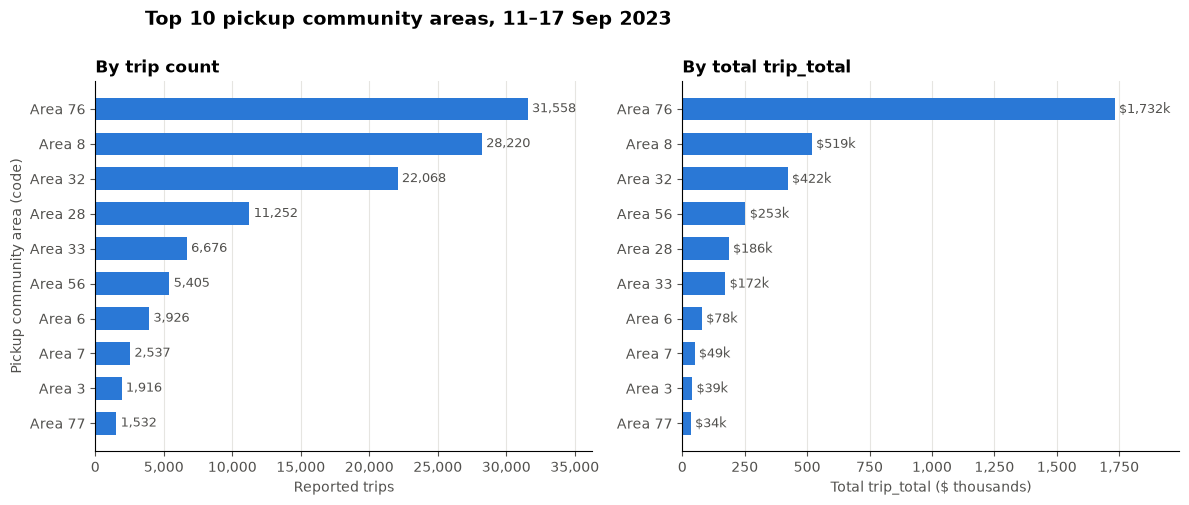

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=False)
for ax, data, col, title, xlabel, lab in [
    (axes[0], top_trips, 'trips', 'By trip count', 'Reported trips', lambda v: f'{v:,.0f}'),
    (axes[1], top_rev, 'revenue', 'By total trip_total', 'Total trip_total ($ thousands)', lambda v: f'${v / 1000:,.0f}k'),
]:
    d_ = data[::-1]
    vals = d_[col]
    ax.barh([f'Area {a}' for a in d_.index], vals, color=BLUE, height=0.65)
    for y, v in enumerate(vals):
        ax.text(v + vals.max() * 0.01, y, lab(v), va='center', fontsize=9, color='#52514e')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, vals.max() * 1.15)
    ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
    if col == 'revenue':
        ax.xaxis.set_major_formatter(lambda v, _: f'{v / 1000:,.0f}')
    else:
        ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
axes[0].set_ylabel('Pickup community area (code)')
fig.suptitle('Top 10 pickup community areas, 11–17 Sep 2023', x=0.125, ha='left', fontsize=14, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig('figures/analysis/03_top_pickup_areas.png', dpi=150, bbox_inches='tight')
plt.show()

**Takeaway (Q2).** Trip starts are very concentrated: three community areas (76, 8 and 32) generate 60% of all reported trips, and the top ten generate 85%. The top-10 lists by trips and by revenue contain exactly the same ten areas. Area 76 stands out most: 23% of trips but 43% of revenue, because its average trip total ($55) is about three times that of areas 8 and 32 (about $18–19); area 56 shows the same pattern on a smaller scale ($47 average, moving it from 7th by trips to 4th by revenue). 2.8% of trips have no pickup community area; they average a higher fare ($37 vs $30) and carry 3.5% of revenue. Note: "revenue" here means `trip_total`, which includes tips, tolls and extras.

## 5. Q3 — How do riders pay and tip?

* "Revenue" = sum of `trip_total` (fare + tips + tolls + extras + any small un-itemised surcharge). "Average fare" = mean of `fare` only.
* Tip % is computed two ways: **total tips ÷ total fare** (a ratio of sums, robust to tiny-fare trips) and the **median of per-trip tip %**. Tips are recorded for `Credit Card` and `Mobile` payments but effectively not for `Cash`, `Prcard` or `Unknown` (see the table: under 6% of those trips show any tip), so tip rates are **only meaningful for Credit Card and Mobile**, and the others must not be compared with them.

In [11]:
g = df.groupby('payment_type')
pay = pd.DataFrame({
    'trips': g.size(),
    'trip_share_%': g.size() / n * 100,
    'revenue': g.trip_total.sum(),
    'revenue_share_%': g.trip_total.sum() / df.trip_total.sum() * 100,
    'avg_fare': g.fare.mean(),
    'total_fare': g.fare.sum(),
    'total_tips': g.tips.sum(),
})
pay['tips_%_of_fare (sum ratio)'] = pay.total_tips / pay.total_fare * 100
pay['median_trip_tip_%'] = g.apply(lambda x: (x.tips / x.fare * 100).median())
pay['trips_with_tip_%'] = g.apply(lambda x: (x.tips > 0).mean() * 100)
pay = pay.sort_values('trips', ascending=False)
fmt = {'trips': '{:,.0f}'.format, 'revenue': '${:,.0f}'.format, 'avg_fare': '${:.2f}'.format, 'total_fare': '${:,.0f}'.format,
       'total_tips': '${:,.0f}'.format, 'trip_share_%': '{:.1f}'.format, 'revenue_share_%': '{:.1f}'.format,
       'tips_%_of_fare (sum ratio)': '{:.1f}'.format, 'median_trip_tip_%': '{:.1f}'.format, 'trips_with_tip_%': '{:.1f}'.format}
print(pay.to_string(formatters=fmt))
print(f"\nAll trips: {n:,} trips, ${df.trip_total.sum():,.0f} revenue, average fare ${df.fare.mean():.2f}")

card = df[df.payment_type.isin(['Credit Card', 'Mobile'])]
print(f"\nTip-recording types pooled (Credit Card + Mobile): {len(card):,} trips ({len(card) / n:.1%}); tips = {card.tips.sum() / card.fare.sum():.1%} of fare; "
      f"median per-trip tip {(card.tips / card.fare).median():.1%}; {(card.tips > 0).mean():.1%} of trips have a tip")
cash = df[df.payment_type == 'Cash']
print(f"Cash: {len(cash):,} trips; {(cash.tips > 0).mean():.2%} have any recorded tip -> tips effectively unrecorded")
pr = df[df.payment_type == 'Prcard']
print(f"Prcard: {len(pr):,} trips; {(pr.tips > 0).mean():.2%} have any recorded tip -> also effectively unrecorded")

              trips trip_share_%    revenue revenue_share_% avg_fare total_fare total_tips tips_%_of_fare (sum ratio) median_trip_tip_% trips_with_tip_%
payment_type                                                                                                                                            
Credit Card  60,287         44.6 $2,421,800            59.7   $29.04 $1,750,847   $386,867                       22.1              22.6             93.6
Cash         39,593         29.3   $791,908            19.5   $18.33   $725,725       $949                        0.1               0.0              0.4
Mobile       18,594         13.7   $413,943            10.2   $17.81   $331,137    $67,718                       20.5              22.2             92.7
Prcard       11,961          8.8   $307,514             7.6   $25.43   $304,200     $2,266                        0.7               0.0              5.2
Unknown       4,783          3.5   $115,614             2.9   $24.04   $114,983   

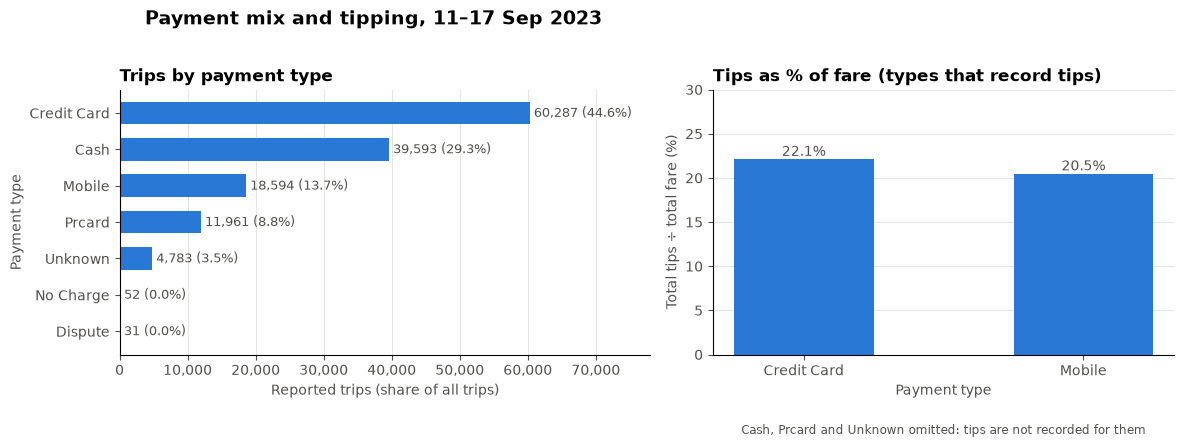

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={'width_ratios': [1.15, 1]})
ax = axes[0]
p_ = pay.sort_values('trips')
ax.barh(p_.index, p_.trips, color=BLUE, height=0.62)
for y, (v, sh) in enumerate(zip(p_.trips, p_['trip_share_%'])):
    ax.text(v + 600, y, f'{v:,.0f} ({sh:.1f}%)', va='center', fontsize=9, color='#52514e')
ax.set_title('Trips by payment type', fontsize=12)
ax.set_xlabel('Reported trips (share of all trips)')
ax.set_ylabel('Payment type')
ax.set_xlim(0, 78000)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}')
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)

ax = axes[1]
t_ = pay.loc[['Credit Card', 'Mobile']]
ax.bar(t_.index, t_['tips_%_of_fare (sum ratio)'], color=BLUE, width=0.5)
for x, v in enumerate(t_['tips_%_of_fare (sum ratio)']):
    ax.text(x, v + 0.4, f'{v:.1f}%', ha='center', fontsize=10, color='#52514e')
ax.set_title('Tips as % of fare (types that record tips)', fontsize=12)
ax.set_xlabel('Payment type')
ax.set_ylabel('Total tips ÷ total fare (%)')
ax.set_ylim(0, 30)
ax.text(0.5, -0.30, 'Cash, Prcard and Unknown omitted: tips are not recorded for them', transform=ax.transAxes, ha='center', fontsize=8.5, color='#52514e')
fig.suptitle('Payment mix and tipping, 11–17 Sep 2023', x=0.125, ha='left', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/analysis/04_payment_and_tips.png', dpi=150, bbox_inches='tight')
plt.show()